In [1]:
import pandas as pd
from datetime import datetime
import os
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

In [2]:
# Load the CSV file into a pandas DataFrame
cPath = os.path.dirname(os.path.realpath('./New/'))
file_path = cPath + '/Combined_Terminal_Label.csv'
print(file_path)
myData = pd.read_csv(file_path, parse_dates=['DateTime'], date_format='%Y-%m-%d %H:%M:%S')
myData.set_index('DateTime', drop = False, inplace=True)
# print(myData.head)
print(myData.index.name)
print(myData)

/home/homayoun-valafar/Dropbox/Projects/VisualCode/Python/CAE/New/KWH_based/Combined_Terminal_Label.csv
DateTime
                               DateTime  KWH11    KW  Year     Delta     label
DateTime                                                                      
2014-07-01 00:15:00 2014-07-01 00:15:00  357.5  1430  2014  0.005000  sOffPeak
2014-07-01 00:30:00 2014-07-01 00:30:00  362.0  1448  2014 -0.012778  sOffPeak
2014-07-01 00:45:00 2014-07-01 00:45:00  350.5  1402  2014 -0.006667  sOffPeak
2014-07-01 01:00:00 2014-07-01 01:00:00  344.5  1378  2014 -0.022222  sOffPeak
2014-07-01 01:15:00 2014-07-01 01:15:00  324.5  1298  2014 -0.000556  sOffPeak
...                                 ...    ...   ...   ...       ...       ...
2024-12-31 23:00:00 2024-12-31 23:00:00  223.5   894  2024 -0.027778  wOffPeak
2024-12-31 23:15:00 2024-12-31 23:15:00  198.5   794  2024  0.013889  wOffPeak
2024-12-31 23:30:00 2024-12-31 23:30:00  211.0   844  2024  0.008889  wOffPeak
2024-12-31 23:45:0

In [3]:
# First, create a new index in each dataframe ignoring the year
def strip_year(df):
    df = df.copy()
    df['datetime_wo_year'] = df.index.to_series().apply(lambda x: x.replace(year=2000))  # 2000 is arbitrary
    return df.set_index('datetime_wo_year')

# Apply to all three dataframes
Y19 = myData.loc["2019"]
Y20 = myData.loc["2020"]
Y21 = myData.loc["2021"]
Y22 = myData.loc["2022"]
Y23 = myData.loc["2023"]
Y24 = myData.loc["2024"]
Y19_new = strip_year(Y19).rename(columns={'KWH11': 'KWH11_Y19'})
Y20_new = strip_year(Y20).rename(columns={'KWH11': 'KWH11_Y20'})
Y21_new = strip_year(Y21).rename(columns={'KWH11': 'KWH11_Y21'})
Y22_new = strip_year(Y22).rename(columns={'KWH11': 'KWH11_Y22'})
Y23_new = strip_year(Y23).rename(columns={'KWH11': 'KWH11_Y23'})
Y24_new = strip_year(Y24).rename(columns={'KWH11': 'KWH11_Y24'})

# Join on the new index (same arbitrary year, matching month/day/hour/minute/second)
merged = Y19_new[['KWH11_Y19']].join(
    Y20_new[['KWH11_Y20']], how='inner'
).join(
    Y21_new[['KWH11_Y21']], how='inner'
).join(
    Y22_new[['KWH11_Y22']], how='inner'
).join(
    Y23_new[['KWH11_Y23']], how='inner'
).join(
    Y24_new[['KWH11_Y24']], how='inner'
)


# Optional: reset index or keep datetime_wo_year
merged.index.name = 'Time'
print(merged)


                     KWH11_Y19  KWH11_Y20  KWH11_Y21  KWH11_Y22  KWH11_Y23  \
Time                                                                         
2000-01-01 00:00:00      176.0      143.0      133.5      248.0      155.5   
2000-01-01 00:15:00      176.0      140.5      134.5      247.0      185.0   
2000-01-01 00:30:00      174.5      145.0      155.0      198.0      185.0   
2000-01-01 00:45:00      175.5      143.0      134.0      186.5      179.5   
2000-01-01 01:00:00      175.0      148.5      139.5      188.0      178.5   
...                        ...        ...        ...        ...        ...   
2000-12-31 22:45:00      148.0      142.5      249.5      180.0      192.5   
2000-12-31 23:00:00      143.5      153.0      251.5      187.5      182.0   
2000-12-31 23:15:00      145.5      146.5      248.0      185.0      167.0   
2000-12-31 23:30:00      153.0      129.0      248.5      179.5      172.5   
2000-12-31 23:45:00      149.5      149.0      248.0      176.5 

In [6]:
X = merged[['KWH11_Y19', 'KWH11_Y20', 'KWH11_Y21', 'KWH11_Y22', 'KWH11_Y23', 'KWH11_Y24']].to_numpy()
y = merged['KWH11_Y24'].to_numpy()
print(type(X), X.shape)
print(type(y), y.shape)
model = LinearRegression()
model.fit(X, y)
print(model.intercept_, model.coef_)

<class 'numpy.ndarray'> (34956, 6)
<class 'numpy.ndarray'> (34956,)
0.0 [1.13765540e-15 6.66133815e-16 6.93889390e-16 4.16333634e-16
 1.11022302e-15 1.00000000e+00]


In [7]:
# Step 3: Make predictions using the linear model
y_pred = model.predict(X)  # Predicted values for original X

In [8]:
# Step 4: Fitness evaluation by comparing y (the ideal output) and y_pred (the predicted output)
# Calculate fitness metrics of R², Mean Square Error (MSE), and Root Mean Square Error (rmse) score
r2 = r2_score(y, y_pred)  # Coefficient of determination (R² score)
mse = mean_squared_error(y, y_pred)  # Mean Squared Error
rmse = np.sqrt(mse)  # Root Mean Squared Error

print(f"R² Score: {r2:.4f}")
print(f"Mean Squared Error (MSE): {mse:.4f}")
print(f"Root Mean Squared Error (RMSE): {rmse:.4f}")

R² Score: 1.0000
Mean Squared Error (MSE): 0.0000
Root Mean Squared Error (RMSE): 0.0000


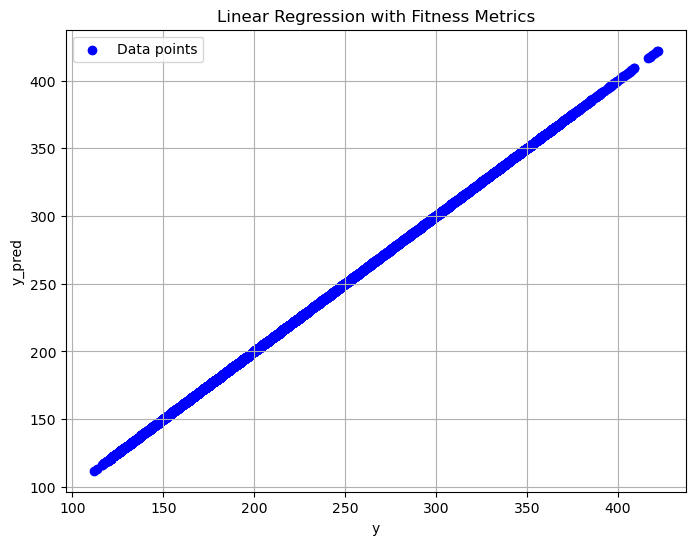

In [9]:
# Step 5: Visualization
plt.figure(figsize=(8, 6))
plt.scatter(y, y_pred, color="blue", label="Data points")
#plt.plot(X, y_pred, color="red", label="Regression line")
plt.xlabel("y")
plt.ylabel("y_pred")
plt.title("Linear Regression with Fitness Metrics")
plt.legend()
plt.grid(True)
plt.show()

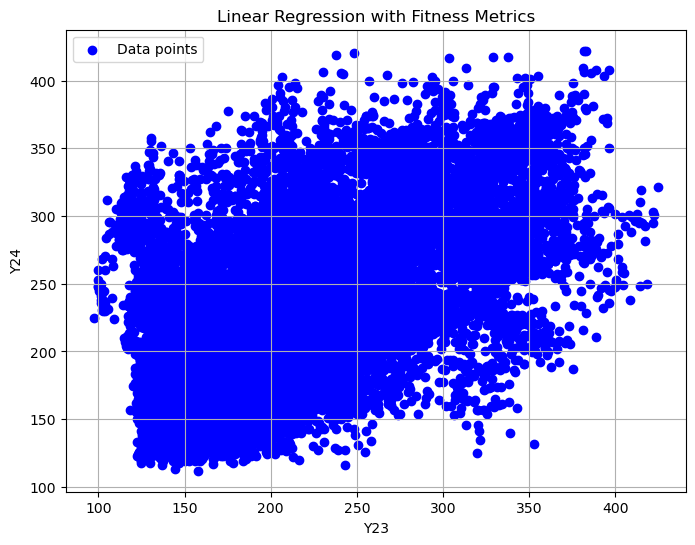

In [10]:
# Step 5: Visualization
plt.figure(figsize=(8, 6))
plt.scatter(merged['KWH11_Y23'], merged['KWH11_Y24'], color="blue", label="Data points")
plt.xlabel("Y23")
plt.ylabel("Y24")
plt.title("Linear Regression with Fitness Metrics")
plt.legend()
plt.grid(True)
plt.show()

In [11]:
import plotly.graph_objects as go

# Create the figure
fig = go.Figure()

# Add first usage trace
fig.add_trace(go.Scatter(
    x=merged.index,  # assuming time and date are in the index
    y=merged['KWH11_Y24'],
    mode='lines',
    name='Actual'
))

# Add second usage trace
fig.add_trace(go.Scatter(
    x=merged.index,
    y=y_pred,
    mode='lines',
    name='Predicted'
))

# Customize layout
fig.update_layout(
    title='Actual versus Predicted Usage for Jan-Apr 2025',
    xaxis_title='Time',
    yaxis_title='Usage',
    legend_title='Legend',
    template='plotly_white'
)

# Show the figure
fig.show()


In [12]:
# Generate time index for 2025 in increments of 15 minutes
time_index_2025 = pd.date_range(start='2025-01-01', end='2025-12-31 23:45:00', freq='15T') 
print(time_index_2025)

DatetimeIndex(['2025-01-01 00:00:00', '2025-01-01 00:15:00',
               '2025-01-01 00:30:00', '2025-01-01 00:45:00',
               '2025-01-01 01:00:00', '2025-01-01 01:15:00',
               '2025-01-01 01:30:00', '2025-01-01 01:45:00',
               '2025-01-01 02:00:00', '2025-01-01 02:15:00',
               ...
               '2025-12-31 21:30:00', '2025-12-31 21:45:00',
               '2025-12-31 22:00:00', '2025-12-31 22:15:00',
               '2025-12-31 22:30:00', '2025-12-31 22:45:00',
               '2025-12-31 23:00:00', '2025-12-31 23:15:00',
               '2025-12-31 23:30:00', '2025-12-31 23:45:00'],
              dtype='datetime64[ns]', length=35040, freq='15T')


In [14]:
df_2025 = pd.DataFrame(index=time_index_2025)
print(df_2025.head())
df_2025["Predicted_Usage"] = model.predict(X)



Empty DataFrame
Columns: []
Index: [2025-01-01 00:00:00, 2025-01-01 00:15:00, 2025-01-01 00:30:00, 2025-01-01 00:45:00, 2025-01-01 01:00:00]


ValueError: Length of values (34956) does not match length of index (35040)